In [88]:
import pybamm
import matplotlib.pyplot as plt
import numpy as np

In [89]:
parameter_values = pybamm.ParameterValues("Chen2020") #Importing parameter values from the parameter set
parameter_values.set_initial_state(0) # Set initial state of charge to 0%
initial_soc = 0
Q_nom = parameter_values["Nominal cell capacity [A.h]"]
C_rates = [1, 2, 3, 4] # Define the C-rates for the charging experiment
sols = {}

In [90]:
for C_rate in C_rates:
    CCCV_Charging = pybamm.Experiment([
        f"Charge at {C_rate}C until 4.2 V",
        "Hold at 4.2 V until C/20",
    ])
    sim = pybamm.Simulation(pybamm.lithium_ion.DFN(), experiment=CCCV_Charging, parameter_values=parameter_values)
    sols[C_rate] = sim.solve()

In [91]:
CCCV_Charging = pybamm.Experiment([
    f"Charge at {C_rate}C until 4.2V", ## CC Phase will charge the battery at C_rate until the voltage reaches 4.2V
    f"Hold at 4.2 V until {Q_nom * 0.05:.1f} mA"   # → "Hold at 4.2 V until 0.2 mA"
])

In [92]:
model = pybamm.lithium_ion.DFN() # Create a DFN model
# Create a simulation object with the model, experiment, and parameter values
sim = pybamm.Simulation(model, experiment=CCCV_Charging, parameter_values=parameter_values) 
sol = sim.solve() # Solve the simulation

CC Phase Time end SoC for 1C: 70.79% at time 42.47 min
CV Phase Time for 1C: 30.66 min
Final SoC for 1C: 101.45% at time 100.61 min
CC Phase Time end SoC for 2C: 47.07% at time 14.12 min
CV Phase Time for 2C: 54.32 min
Final SoC for 2C: 101.39% at time 84.90 min
CC Phase Time end SoC for 3C: 26.77% at time 5.35 min
CV Phase Time for 3C: 74.59 min
Final SoC for 3C: 101.36% at time 83.07 min
CC Phase Time end SoC for 4C: 13.76% at time 2.06 min
CV Phase Time for 4C: 87.58 min
Final SoC for 4C: 101.34% at time 82.83 min


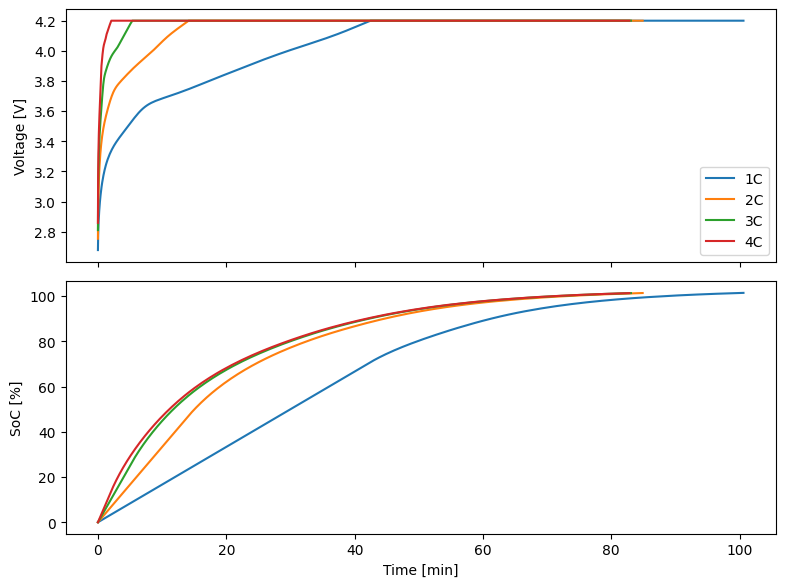

In [93]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(8, 6))
for C_rate, sol in sols.items():
    t   = sol["Time [min]"].entries
    soc = (initial_soc - sol["Discharge capacity [A.h]"].entries / Q_nom) * 100
    ax1.plot(t, sol["Voltage [V]"].entries, label=f"{C_rate}C")
    ax2.plot(t, soc, label=f"{C_rate}C")
    t_end = sol.cycles[1]["Time [min]"].entries[-1]
    t_first_end = sol.cycles[0]["Time [min]"].entries[-1]
    t_second_end = sol.cycles[1]["Time [min]"].entries[-1]
    soc_end = np.interp(t_end, t, soc)
    soc_first_end = np.interp(t_first_end, t, soc)
    soc_second_end = np.interp(t_second_end, t, soc)
    CV_Phase_Time = soc_second_end - soc_first_end 
    print(f"CC Phase Time end SoC for {C_rate}C: {soc_first_end:.2f}% at time {t_first_end:.2f} min")
    print(f"CV Phase Time for {C_rate}C: {CV_Phase_Time:.2f} min")
    print(f"Final SoC for {C_rate}C: {soc_end:.2f}% at time {t_end:.2f} min")


ax1.set_ylabel("Voltage [V]");  ax1.legend()
ax2.set_ylabel("SoC [%]"); ax2.set_xlabel("Time [min]")
plt.tight_layout(); plt.show()